# Session 3, Extra: Fair vs Loaded Dice, and Why the CLT Doesn't Care

**Optional, self-paced companion to slide 9 ("A quick taste: does one die's average behave?").**

That slide showed a *fair* die's running average settling near 3.5 after 30 rolls. This notebook asks the harder question: does that still happen if the die is rigged? Two dice, one fair and one deliberately loaded, run through every step of today's Central Limit Theorem leg, so you can see for yourself that the CLT does not care what you start with.

## Step 1, two very different starting points

**Predict before you compute:** look at the two bar charts below before you run anything else. Which die's *single-roll* average do you expect to land further from 3.5? Say a number for each out loud.

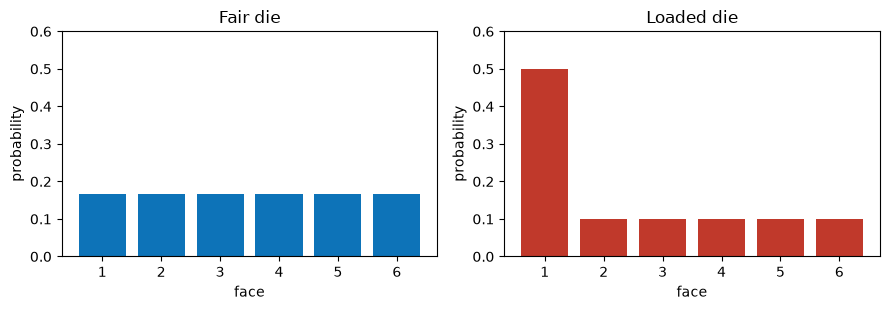

In [1]:
# --- Two dice: one fair, one loaded ---------------------------------
import numpy as np, matplotlib.pyplot as plt

FACES = np.arange(1, 7)
FAIR_PROBS = np.full(6, 1 / 6)
LOADED_PROBS = np.array([0.50, 0.10, 0.10, 0.10, 0.10, 0.10])   # loaded toward 1

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].bar(FACES, FAIR_PROBS, color='#0D73B8'); ax[0].set_title('Fair die'); ax[0].set_ylim(0, 0.6)
ax[1].bar(FACES, LOADED_PROBS, color='#C0392B'); ax[1].set_title('Loaded die'); ax[1].set_ylim(0, 0.6)
for a in ax:
    a.set_xlabel('face'); a.set_ylabel('probability')
plt.tight_layout(); plt.show()

In [2]:
# --- Each die's true mean and sd, calculated directly from its probabilities ---
def die_mean_sd(probs):
    mu = np.sum(FACES * probs)
    var = np.sum(probs * (FACES - mu) ** 2)
    return mu, np.sqrt(var)

fair_mu, fair_sd = die_mean_sd(FAIR_PROBS)
loaded_mu, loaded_sd = die_mean_sd(LOADED_PROBS)
print(f'fair die:   mean {fair_mu:.2f}   sd {fair_sd:.2f}')
print(f'loaded die: mean {loaded_mu:.2f}   sd {loaded_sd:.2f}')

fair die:   mean 3.50   sd 1.71
loaded die: mean 2.50   sd 1.80


## Step 2, one die at a time: does the average settle?

Slide 9 showed this for the fair die alone. **Predict before you compute:** where do you expect the loaded die's running average to settle, and after roughly how many rolls?

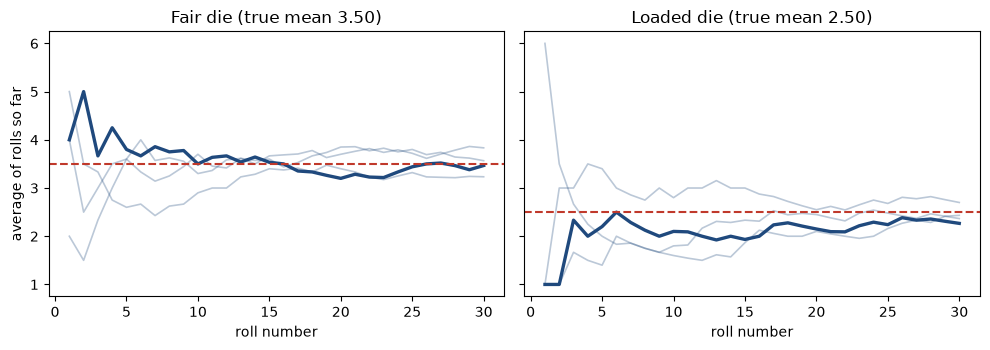

In [3]:
# --- Running average over 30 rolls, both dice, four runs each --------
def running_average(probs, n=30, runs=4, seed=None):
    r = np.random.default_rng(seed)
    return [np.cumsum(r.choice(FACES, size=n, p=probs)) / np.arange(1, n + 1) for _ in range(runs)]

xs = np.arange(1, 31)
fair_runs = running_average(FAIR_PROBS, seed=1)
loaded_runs = running_average(LOADED_PROBS, seed=2)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for i, run in enumerate(fair_runs):
    ax[0].plot(xs, run, color='#1F497D', lw=2.4 if i == 0 else 1.2, alpha=1 if i == 0 else 0.3)
ax[0].axhline(fair_mu, color='#C0392B', ls='--'); ax[0].set_title(f'Fair die (true mean {fair_mu:.2f})')
for i, run in enumerate(loaded_runs):
    ax[1].plot(xs, run, color='#1F497D', lw=2.4 if i == 0 else 1.2, alpha=1 if i == 0 else 0.3)
ax[1].axhline(loaded_mu, color='#C0392B', ls='--'); ax[1].set_title(f'Loaded die (true mean {loaded_mu:.2f})')
for a in ax:
    a.set_xlabel('roll number')
ax[0].set_ylabel('average of rolls so far')
plt.tight_layout(); plt.show()

## Step 3, not one die, many: the sum of n dice

Now switch from averaging one die over time to a different kind of average: roll **n** dice at once, add them up, and repeat that thousands of times to see the *distribution of the sum*. **Predict before you compute:** at roughly what n do you expect the fair die's sum to start looking like a bell curve? What about the loaded die, slower, faster, or about the same?

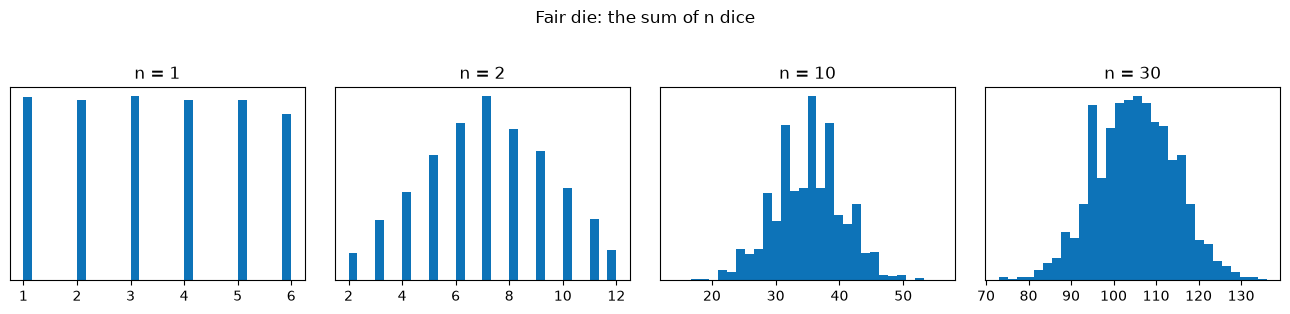

In [4]:
# --- Sums of n dice, many trials, fair die ---------------------------
def sum_of_n_dice(probs, n, trials=4000, seed=None):
    r = np.random.default_rng(seed)
    return r.choice(FACES, size=(trials, n), p=probs).sum(axis=1)

fig, ax = plt.subplots(1, 4, figsize=(13, 3))
for a, n in zip(ax, (1, 2, 10, 30)):
    sums = sum_of_n_dice(FAIR_PROBS, n, seed=10 + n)
    a.hist(sums, bins=30, color='#0D73B8'); a.set_title(f'n = {n}'); a.set_yticks([])
fig.suptitle('Fair die: the sum of n dice', y=1.03)
plt.tight_layout(); plt.show()

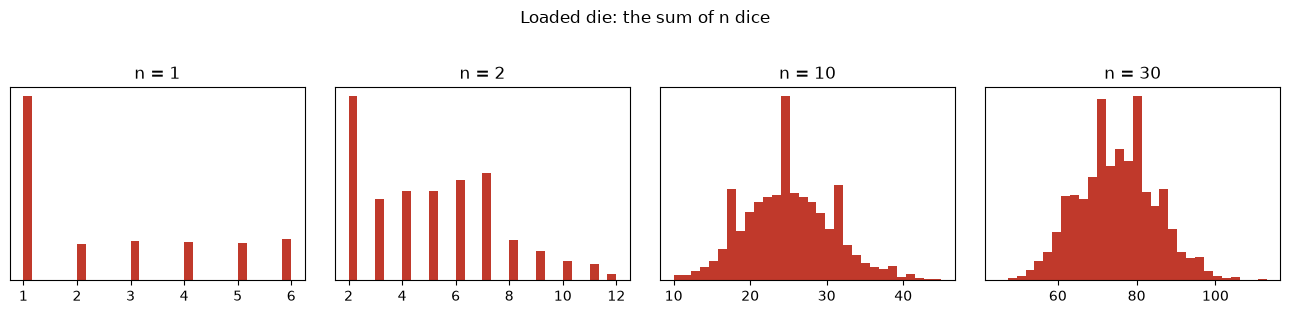

In [5]:
# --- Sums of n dice, many trials, loaded die --------------------------
fig, ax = plt.subplots(1, 4, figsize=(13, 3))
for a, n in zip(ax, (1, 2, 10, 30)):
    sums = sum_of_n_dice(LOADED_PROBS, n, seed=20 + n)
    a.hist(sums, bins=30, color='#C0392B'); a.set_title(f'n = {n}'); a.set_yticks([])
fig.suptitle('Loaded die: the sum of n dice', y=1.03)
plt.tight_layout(); plt.show()

Same story, two very different starting bar charts. By n = 30, both sums look like a bell, just centred and spread differently. **That is the whole Central Limit Theorem:** the shape you start with stops mattering once you sum enough of it.

## Step 4, put numbers on it

Two formulas explain both pictures above. For the sum of n dice:

- **mean of the sum** = n x (the die's own mean)
- **sd of the sum** = sqrt(n) x (the die's own sd)

Check these against the simulation for both dice.

In [6]:
# --- Verify mean(sum) = n*mu and sd(sum) = sqrt(n)*sigma, both dice ---
for name, probs, mu, sd in [('fair', FAIR_PROBS, fair_mu, fair_sd),
                              ('loaded', LOADED_PROBS, loaded_mu, loaded_sd)]:
    for n in (10, 30):
        sums = sum_of_n_dice(probs, n, trials=20000, seed=99)
        pred_mean, pred_sd = n * mu, np.sqrt(n) * sd
        print(f'{name:6s} n={n:2d}:  simulated mean {sums.mean():6.2f} (predicted {pred_mean:6.2f})   '
              f'simulated sd {sums.std(ddof=1):5.2f} (predicted {pred_sd:5.2f})')

fair   n=10:  simulated mean  35.06 (predicted  35.00)   simulated sd  5.40 (predicted  5.40)
fair   n=30:  simulated mean 105.04 (predicted 105.00)   simulated sd  9.36 (predicted  9.35)
loaded n=10:  simulated mean  25.05 (predicted  25.00)   simulated sd  5.71 (predicted  5.70)
loaded n=30:  simulated mean  75.04 (predicted  75.00)   simulated sd  9.82 (predicted  9.87)


## Step 5, the worked question, for both dice

Slide 9's own territory, properly worked: roll a **fair** die 100 times and add up the results. What range are you 95% sure that sum falls in? **Predict before you compute**, then check the fair die's answer below, then work out the loaded die's range yourself before reading the second line.

In [7]:
# --- 95% range for the sum of 100 rolls, both dice --------------------
def range_95(mu, sd, n):
    sum_mean, sum_sd = n * mu, np.sqrt(n) * sd
    return sum_mean - 2 * sum_sd, sum_mean + 2 * sum_sd

for name, mu, sd in [('fair', fair_mu, fair_sd), ('loaded', loaded_mu, loaded_sd)]:
    lo, hi = range_95(mu, sd, 100)
    print(f'{name} die, sum of 100 rolls: 95% range is about {lo:.0f} to {hi:.0f}')

fair die, sum of 100 rolls: 95% range is about 316 to 384
loaded die, sum of 100 rolls: 95% range is about 214 to 286


## Step 6 (stretch), design your own die

Edit `MY_PROBS` below, six numbers that add up to 1, and rerun. However strange you make it, the sum of 30 still comes out looking like a bell.

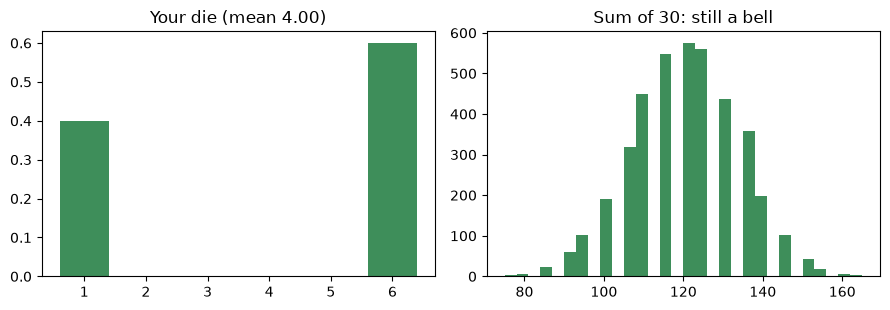

In [8]:
MY_PROBS = np.array([0.40, 0.00, 0.00, 0.00, 0.00, 0.60])   # edit me, must sum to 1
assert np.isclose(MY_PROBS.sum(), 1), 'probabilities must sum to 1'

my_mu, my_sd = die_mean_sd(MY_PROBS)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].bar(FACES, MY_PROBS, color='#3E8E5A'); ax[0].set_title(f'Your die (mean {my_mu:.2f})')
sums30 = sum_of_n_dice(MY_PROBS, 30, seed=5)
ax[1].hist(sums30, bins=30, color='#3E8E5A'); ax[1].set_title('Sum of 30: still a bell')
plt.tight_layout(); plt.show()

## Wrap: the three conditions, and the Claude beat

Nothing here used the shape of the die, only that every roll was **independent** of the others, every roll came from the **same** distribution (even a weird one), and that distribution's spread was a normal, **finite** number, not some uncapped one. Those are the three conditions the Central Limit Theorem actually needs.

**Claude beat:** paste your own `MY_PROBS` chart and ask Claude to explain, in plain English, why summing enough of it still produces a bell, even though the single-roll chart does not look like one at all.

Same mechanism, three different costumes this session: the room's own countries-visited data, a skewed transaction ledger, and now a rigged die of your own design.